# Metis full-dataset EDA

Runs or displays the full-dataset EDA (revision pinned in `scripts/full_eda_ingest.py`). Outputs here are **feature-only tables and figures**; no message content, instructions or retrieved text is ever displayed. Reproduce: see `experiments/full_eda/README.md`. Set `SMOKE = True` to run the same pipeline on the first 3,000 messages of one shard; set `RERUN = True` to rebuild the derived tables (about 10 minutes on 8 CPUs; needs the raw snapshot under `data/full_data/raw/`, fetched with `HF_TOKEN`).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

SMOKE = False  # True: 3,000-message smoke run of every phase
RERUN = False  # True: rebuild derived tables with the scripts below
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
TAB = Path("reports/full_eda") / ("tables_smoke" if SMOKE else "tables")
flag = ["--smoke"] if SMOKE else []
print("repo root:", ROOT, "| smoke:", SMOKE, "| rerun:", RERUN)

repo root: /Users/kimiakayvan/Desktop/Metis/metis-auto | smoke: False | rerun: False


In [2]:
if RERUN:
    steps = [
        ["scripts/full_eda_ingest.py", *flag],
        ["scripts/full_eda_requests.py", *flag],
        [
            "scripts/full_eda_analyze.py",
            *flag,
            "--phases",
            "scope,language,tokens,history,rag,cache,routing,reduction",
            "--tag",
            "a",
        ],
    ]
    if not SMOKE:
        steps += [
            ["scripts/full_eda_analyze.py", "--phases", "semantic", "--tag", "b"],
            ["scripts/full_eda_analyze.py", "--phases", "extras", "--tag", "c"],
            ["scripts/full_eda_figures.py"],
            ["scripts/full_eda_render.py"],
        ]
    for s in steps:
        print(">>", " ".join(s))
        r = subprocess.run([sys.executable, *s], capture_output=True, text=True)
        print(r.stdout[-400:], r.stderr[-400:])
else:
    print("using existing derived tables")

using existing derived tables


## Provenance and scope

In [3]:
import json

mf = json.load(
    open("data/derived/full_eda" + ("_smoke" if SMOKE else "") + "/manifest.json")
)
{
    k: mf[k]
    for k in (
        "revision",
        "smoke",
        "config_hash",
        "bots",
        "sessions",
        "python",
        "pandas",
        "pyarrow",
        "cpus",
        "elapsed_s",
        "created_utc",
    )
}

{'revision': '30f578f283b903cdbd06cd1b5f7f962f76452ded',
 'smoke': False,
 'config_hash': '6402c073c3fc4715',
 'bots': 1830,
 'sessions': 80179,
 'python': '3.13.5',
 'pandas': '3.0.6',
 'pyarrow': '25.0.1',
 'cpus': 8,
 'elapsed_s': 175.2,
 'created_utc': '2026-10-30T16:52:19Z'}

In [4]:
led = (
    pd.concat([pd.read_csv(p) for p in sorted(TAB.glob("claims_ledger_[a-z].csv"))])
    if SMOKE
    else pd.read_csv(TAB / "claims_ledger.csv")
)
print(len(led), "claims;", led["evidence_class"].value_counts().to_dict())
led[led.claim_id.str.startswith(("scope.", "integrity.", "pairing."))][
    ["claim_id", "value", "denominator", "evidence_class"]
].head(40)

410 claims; {'observed fact': 204, 'heuristic label': 74, 'simulation': 64, 'metadata-derived': 41, 'hypothetical reconstruction': 27}


,claim_id,value,denominator,evidence_class
0,scope.sessions,80179.000000,NaN,observed fact
1,scope.messages,710640.000000,NaN,observed fact
2,scope.msg_type.USER,0.500908,710640.0,observed fact
3,scope.msg_n.USER,355965.000000,NaN,observed fact
4,scope.msg_type.AI,0.491218,710640.0,observed fact
5,scope.msg_n.AI,349079.000000,NaN,observed fact
6,scope.msg_type.SYSTEM,0.007673,710640.0,observed fact
7,scope.msg_n.SYSTEM,5453.000000,NaN,observed fact
8,scope.msg_type.TOOL,0.000201,710640.0,observed fact
9,scope.msg_n.TOOL,143.000000,NaN,observed fact


## Language, tokens, cost

In [5]:
for name in [
    "language_user_requests",
    "model_usage",
    "cached_token_convention",
    "implied_unit_rates",
]:
    p = TAB / f"{name}.csv"
    if p.exists():
        print(name)
        display(pd.read_csv(p).head(12).round(4))

language_user_requests


,lang,requests,request_share,billed_input_token_share
0,fa,259810,0.7679,0.8566
1,short_uncertain,40163,0.1187,0.0640
2,en,12720,0.0376,0.0200
3,arabic_script_other,12451,0.0368,0.0237
4,fa_en_mixed,12077,0.0357,0.0301
5,structured,984,0.0029,0.0049
6,other,91,0.0003,0.0002
7,finglish,29,0.0001,0.0006


model_usage


,prov,model,requests,sessions,bots,billed_requests,in_tokens,out_tokens,cached_tokens,cost,request_share,cost_share,cached_share,cost_per_billed_request
0,workflow,default,103561,22020,37,2,0.0,0.0,0.0,0.0000,0.2967,0.0000,NaN,0.0000
1,google,gemini-2.5-flash-lite,91358,15049,37,90924,240403296.0,23305650.0,112768.0,35.2639,0.2617,0.0696,0.0005,0.0004
2,openai_chat_completion,gpt-4o-mini,65294,11879,79,65289,75350427.0,9095375.0,14946560.0,17.0982,0.1870,0.0337,0.1984,0.0003
3,google,gemini-2.5-flash,43800,18063,88,43799,736848516.0,28984971.0,201088.0,329.4373,0.1255,0.6501,0.0003,0.0075
4,deepseek,deepseek-v4-flash,26965,1724,153,26965,62667818.0,4491426.0,47756283.0,3.5061,0.0772,0.0069,0.7621,0.0001
5,openai_chat_completion,gpt-5.4-nano,2927,802,2,2927,17600818.0,561064.0,14373120.0,1.6343,0.0084,0.0032,0.8166,0.0006
6,openai_chat_completion,gpt-4.1-mini,2738,1736,6,2733,9576009.0,524228.0,117248.0,4.6774,0.0078,0.0092,0.0122,0.0017
7,grok,grok-4-1-fast,2476,642,107,2476,26659598.0,614731.0,391488.0,23.8663,0.0071,0.0471,0.0147,0.0096
8,openai_chat_completion,gpt-5.1,1797,336,3,1749,2677051.0,1108864.0,40960.0,14.4369,0.0051,0.0285,0.0153,0.0083
9,openai_chat_completion,gpt-5.2,1743,561,8,1737,3499638.0,896699.0,459776.0,18.7541,0.0050,0.0370,0.1314,0.0108


cached_token_convention


,model,share_rows_cached_gt_input,cached_reported_separately
0,claude-4-opus,0.0000,False
1,claude-4-sonnet,0.0000,False
2,claude-haiku-4-5,0.0000,False
3,claude-opus-4-5,0.0000,False
4,claude-opus-4-6,0.0000,False
5,claude-opus-4-7,0.0000,False
6,claude-opus-5,0.5000,False
7,claude-sonnet-4-6,0.0000,False
8,claude-sonnet-5,0.0000,False
9,command-r,0.0000,False


implied_unit_rates


,model,items,input_tokens,output_tokens,cached_tokens,implied_input_per_M,implied_output_per_M,implied_cached_per_M,income_over_cost
0,gemini-2.5-flash-lite,90930,240403296,23305650,112768.0,0.0923,0.3121,0.0746,1.1001
1,gpt-4o-mini,64639,75350427,9095375,14946560.0,0.1030,0.4082,0.0750,1.1000
2,gemini-2.5-flash,53910,736848516,28984971,201088.0,0.1599,0.8659,0.0331,1.1002
3,deepseek-v4-flash,26965,14911535,4490687,47755776.0,0.1214,0.2880,0.0043,1.1000
4,gpt-5.4-nano,2927,3227698,561064,14373120.0,0.2000,1.2500,0.0200,1.1500
5,gpt-4.1-mini,2723,9576009,524228,117248.0,0.0326,0.3655,0.1000,1.1000
6,grok-4-1-fast,2615,26659598,614731,391488.0,0.2301,1.1592,0.1000,1.1000
7,gpt-5.2,1700,3499638,896699,459776.0,1.5611,10.3716,0.1750,1.1000
8,gpt-5.1,1610,2677051,1108864,40960.0,1.1412,5.4768,0.1250,1.1000
9,gemini-2.0-flash,1467,1289797,289583,0.0,0.0933,0.3494,NaN,1.1000


## History, instructions, RAG

In [6]:
for name in [
    "history_growth",
    "history_ratio_to_turn0",
    "instruction_groups_top",
    "rag_chunk_top_lengths",
]:
    p = TAB / f"{name}.csv"
    if p.exists():
        print(name)
        display(pd.read_csv(p).round(4))

history_growth


,tb,requests,median_input_tokens,p90_input_tokens,median_logged_prior_chars,median_instr_chars
0,0,51301,727.0,7348.0,39.0,1436.0
1,1,30829,753.0,10724.8,324.0,1173.0
2,2,18283,998.0,11556.8,815.0,1173.0
3,3-4,24459,1027.0,10058.0,1447.0,1173.0
4,5-9,31304,1023.0,7555.7,2891.0,1173.0
5,10-19,24580,985.0,4283.9,6523.5,1173.0
6,20+,59537,1024.0,10501.4,34506.0,1173.0


history_ratio_to_turn0


,turn_bucket,requests,median_ratio_to_bot_turn0,p90_ratio
0,0,41146,1.0000,1.4508
1,1,22440,1.2796,3.0822
2,2,12857,1.3133,3.0716
3,3-4,18306,1.3631,3.8853
4,5-9,25391,1.4108,5.2740
5,10-19,21335,1.4855,8.0099
6,20+,56981,1.7148,19.5205


instruction_groups_top


,rank,bots,requests,request_share,chars
0,1,35,103550,0.2973,23.0
1,2,1,84809,0.2435,1173.0
2,3,1,32295,0.0927,101.0
3,4,1,10310,0.0296,3589.0
4,5,6,9851,0.0283,2459.0
5,6,10,4989,0.0143,1436.0
6,7,1,4434,0.0127,3731.0
7,8,1,3991,0.0115,7122.0
8,9,1,3697,0.0106,3021.0
9,10,1,3634,0.0104,4261.0


rag_chunk_top_lengths


,chars,rows
0,151,15620
1,84,10067
2,146,9632
3,96,9417
4,150,9341
5,117,8618
6,170,7728
7,93,7715
8,2500,7313
9,2482,7222


## Exact cache replay (candidate hits)

In [7]:
for name in ["exact_cache_funnel", "exact_cache_variants"]:
    p = TAB / f"{name}.csv"
    if p.exists():
        print(name)
        display(pd.read_csv(p).round(4).iloc[:, :14])

exact_cache_funnel


,step,requests
0,all AI messages,349079
1,has_user_text,338325
2,answer_text_and_STOP,336530
3,no_attachments,330003
4,no_tools,329792
5,no_actions,326491
6,timestamps_valid,326491


exact_cache_variants


,variant,scope,eligible_requests,dup_group_occurrences,reusable_upper_bound,pairs,candidate_hits_cold,candidate_hits_ttl_1h,candidate_hits_ttl_24h,candidate_hits_ttl_7d,candidate_hits_cap10k,avoided_cost_candidate,avoided_input_tokens_candidate,avoided_output_tokens_candidate
0,text_only,global,326491,109666.0,101160.0,153796220.0,101157,44077,75043,88262,92429,60.4288,152459607.0,6573165.0
1,text_only,same_user_id,326491,106458.0,97738.0,105279981.0,97735,41398,72360,85425,89542,56.5066,144111536.0,6189390.0
2,text_only,session,326491,30141.0,18222.0,51795.0,18222,12065,14796,16683,16764,13.6086,41024717.0,1820061.0
3,bot+text,global,326491,100316.0,91309.0,56405171.0,91305,37352,66719,80051,84118,41.5412,114001467.0,4945536.0
4,bot+text,same_user_id,326491,100316.0,91309.0,56405171.0,91305,37352,66719,80051,84118,41.5412,114001467.0,4945536.0
5,bot+text,session,326491,30141.0,18222.0,51795.0,18222,12065,14796,16683,16764,13.6086,41024717.0,1820061.0
6,bot+full_history,global,326491,29864.0,27033.0,7624240.0,27030,6511,15703,21664,23362,4.0192,9678003.0,778335.0
7,bot+full_history,same_user_id,326491,29864.0,27033.0,7624240.0,27030,6511,15703,21664,23362,4.0192,9678003.0,778335.0
8,bot+full_history,session,326491,0.0,0.0,0.0,0,0,0,0,0,0.0000,0.0,0.0
9,bot+full_history+rag_set,global,326491,29444.0,26733.0,7622268.0,26730,6481,15597,21511,23191,2.7252,6214295.0,636772.0


## Figures

fig1_language_mix.png


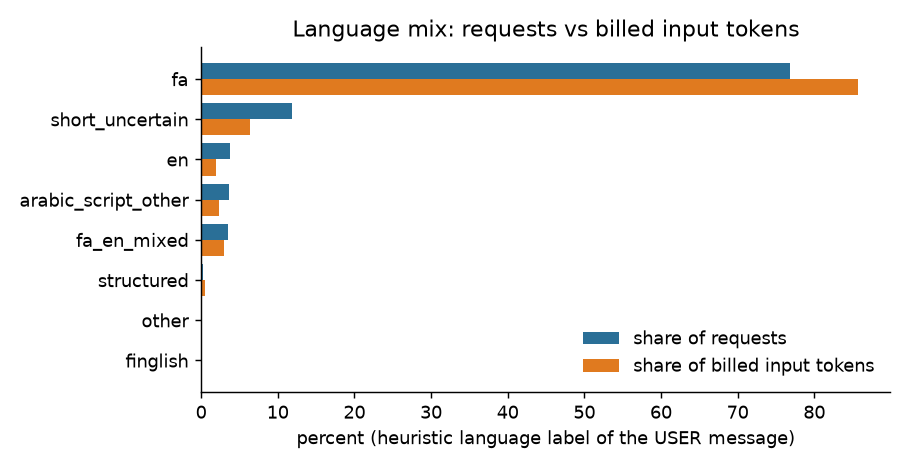

fig2_cost_composition.png


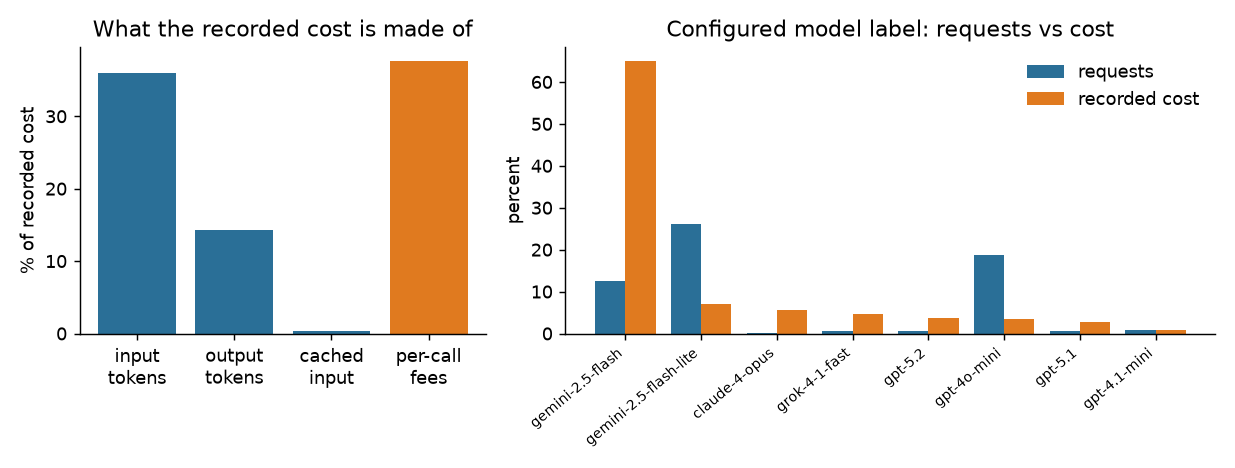

fig3_history_growth.png


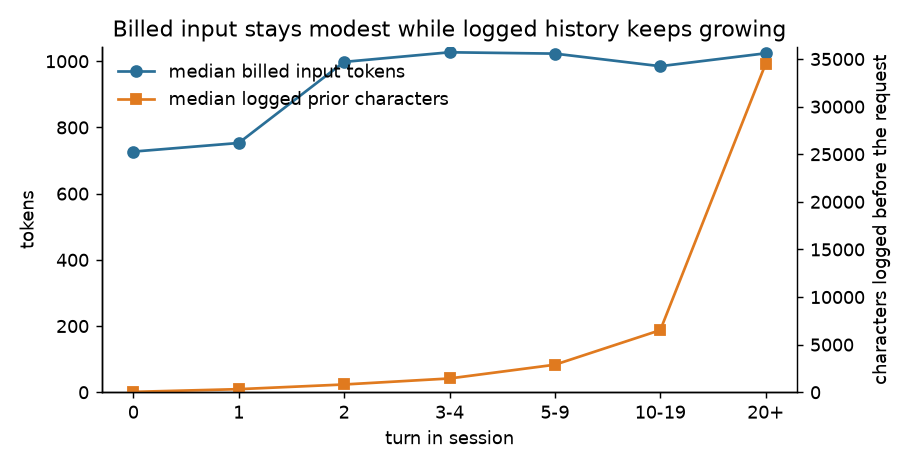

fig4_exact_cache.png


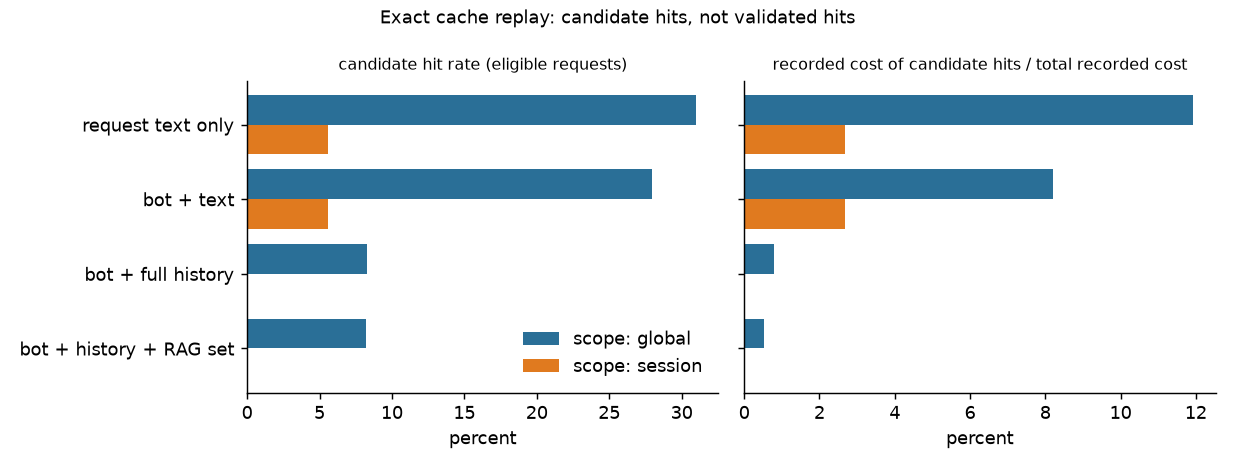

fig5_rag_chunk_lengths.png


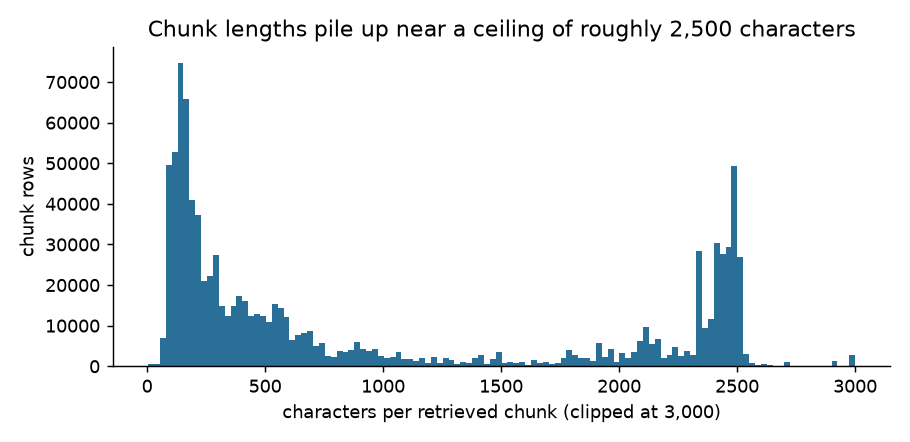

fig6_instruction_groups.png


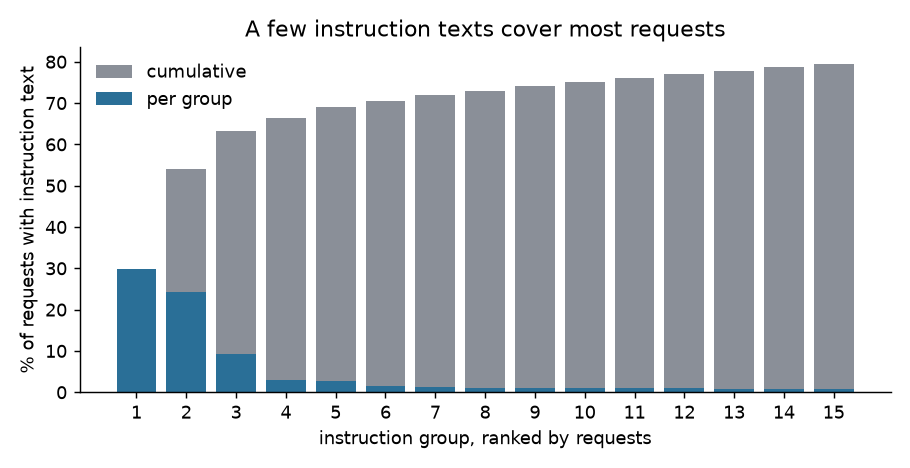

In [8]:
if not SMOKE:
    for f in sorted(Path("reports/full_eda/figures").glob("*.png")):
        print(f.name)
        display(Image(str(f)))

## Consistency check of the written report

Every number in the short report and the findings document must come from the claims ledger.

In [9]:
if not SMOKE:
    r = subprocess.run(
        [sys.executable, "scripts/full_eda_render.py", "--check"],
        capture_output=True,
        text=True,
    )
    print(r.stdout, r.stderr)

check: ok (410 claims)
 
